# 04 — Decisão, explicação e teste

Usa o LightGBM escolhido em `03_modelos.ipynb` (salvo em `models/`), treinado só no período de treino.
1. **4.1** — escolher o limiar de decisão pelo custo, na validação.
2. **4.2** — entender o que o modelo usa.
3. **4.3** — avaliar no teste, uma vez só, com tudo já decidido.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

import graficos

graficos.aplicar_estilo()

modelo = joblib.load("../models/lightgbm.joblib")
validacao = pd.read_parquet("../data/processed/validacao.parquet")

y_validacao = validacao["is_canceled"].to_numpy()
prob_validacao = modelo.predict_proba(validacao[modelo.feature_names_in_])[:, 1]

## 4.1 Limiar de decisão pelo custo

O modelo dá uma probabilidade, mas o hotel precisa de um sim ou não: contatar ou não esta reserva. O corte (limiar) não deve ser 0,5 por padrão — ele depende de quanto custa errar para cada lado.

**Cenário** (suposição, para ser trocada pelos números reais do hotel):
- A ação é contatar a reserva e oferecer um incentivo para confirmar (por exemplo, upgrade ou desconto). Custa **€30 por reserva contatada** — inclusive nas que não iam cancelar.
- Quando a reserva ia mesmo cancelar, o contato **recupera 25% do valor da reserva** (diária × noites): em parte dos casos o hóspede mantém a reserva ou o quarto é revendido a tempo.

Lucro de um limiar = 25% do valor das reservas contatadas que iam cancelar − €30 × reservas contatadas.

*A base não informa a moeda; como os hotéis são em Portugal, os valores são tratados como euro.*

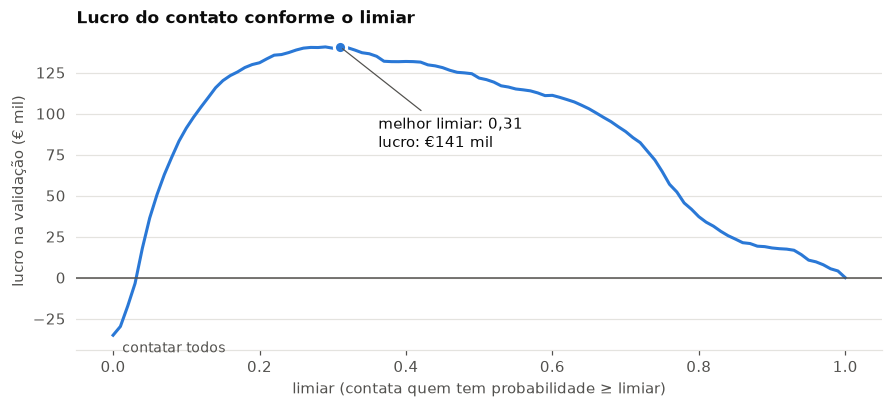

In [2]:
CUSTO_CONTATO = 30  # € por reserva contatada
RECUPERACAO = 0.25  # fração do valor recuperada quando a reserva ia cancelar

valor_reserva = (validacao["adr"] * (validacao["stays_in_weekend_nights"] + validacao["stays_in_week_nights"])).to_numpy()


def lucro(contatar, custo=CUSTO_CONTATO, recuperacao=RECUPERACAO):
    """Lucro de contatar as reservas marcadas em `contatar` (array de True/False)."""
    ganho = (y_validacao[contatar] * recuperacao * valor_reserva[contatar]).sum()
    return ganho - custo * contatar.sum()


limiares = np.round(np.arange(0, 1.0001, 0.01), 2)
curva = pd.Series([lucro(prob_validacao >= t) for t in limiares], index=limiares)
melhor = curva.idxmax()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curva.index, curva / 1000, color=graficos.AZUL, linewidth=2)
ax.axhline(0, color=graficos.TEXTO_SECUNDARIO, linewidth=1)
ax.plot(melhor, curva[melhor] / 1000, "o", color=graficos.AZUL, markersize=8, markeredgecolor="white", markeredgewidth=2)
ax.annotate(f"melhor limiar: {melhor:.2f}\nlucro: €{curva[melhor] / 1000:.0f} mil".replace(".", ","),
            (melhor, curva[melhor] / 1000), xytext=(25, -45), textcoords="offset points", va="top",
            arrowprops=dict(arrowstyle="-", color=graficos.TEXTO_SECUNDARIO, linewidth=0.8))
ax.annotate("contatar todos", (0, curva[0] / 1000), xytext=(6, -4), textcoords="offset points", va="top",
            color=graficos.TEXTO_SECUNDARIO, fontsize=9)
ax.set_xlabel("limiar (contata quem tem probabilidade ≥ limiar)")
ax.set_ylabel("lucro na validação (€ mil)")
ax.set_title("Lucro do contato conforme o limiar")
plt.show()

**Comparando estratégias** — quantas reservas são contatadas, quantas delas iam cancelar de fato, quantos dos cancelamentos são alcançados e o lucro.

In [3]:
estrategias = {
    "não contatar ninguém": np.zeros(len(prob_validacao), dtype=bool),
    "contatar todos": np.ones(len(prob_validacao), dtype=bool),
    "top 10%": prob_validacao >= np.quantile(prob_validacao, 0.90),
    "limiar padrão 0,5": prob_validacao >= 0.5,
    f"limiar escolhido {melhor:.2f}".replace(".", ","): prob_validacao >= melhor,
}

pd.DataFrame({
    nome: {
        "% contatadas": contatar.mean(),
        "das contatadas, iam cancelar": y_validacao[contatar].mean() if contatar.any() else np.nan,
        "dos cancelamentos, alcançados": y_validacao[contatar].sum() / y_validacao.sum(),
        "lucro (€ mil)": lucro(contatar) / 1000,
    }
    for nome, contatar in estrategias.items()
}).T.round(3)

,% contatadas,"das contatadas, iam cancelar","dos cancelamentos, alcançados",lucro (€ mil)
não contatar ninguém,0.000,NaN,0.000,0.000
contatar todos,1.000,0.284,1.000,-35.103
top 10%,0.100,0.741,0.260,85.469
"limiar padrão 0,5",0.186,0.684,0.448,121.650
"limiar escolhido 0,31",0.306,0.588,0.632,140.748


Com o limiar 0,31, o hotel contata 31% das reservas; 59% delas iam cancelar, e o contato alcança 63% de todos os cancelamentos. O lucro é de **€141 mil** nos 4 meses da validação, contra €122 mil com o limiar padrão 0,5, €85 mil contatando só o top 10% e **prejuízo** de €35 mil contatando todo mundo.

A curva é achatada perto do topo: entre ~0,22 e ~0,36 o lucro fica a menos de 5% do máximo, então o valor exato do limiar não é crítico. Como o limiar foi escolhido nesses mesmos dados, o lucro da validação é otimista — o número honesto vem do teste (4.3).

**O limiar muda se o cenário mudar.** Melhor limiar para outros custos de contato e taxas de recuperação:

In [4]:
def melhor_limiar(custo, recuperacao):
    return max(limiares, key=lambda t: lucro(prob_validacao >= t, custo, recuperacao))


pd.DataFrame({
    f"recupera {r:.0%}": {f"contato €{c}": melhor_limiar(c, r) for c in [10, 20, 30, 40]}
    for r in [0.10, 0.25, 0.50]
})

,recupera 10%,recupera 25%,recupera 50%
contato €10,0.22,0.11,0.08
contato €20,0.44,0.18,0.11
contato €30,0.72,0.31,0.15
contato €40,0.81,0.42,0.18


Com contato barato (€10) e boa recuperação, vale contatar quase todo mundo (limiar 0,08); com contato caro (€40) e pouca recuperação, só as reservas de risco altíssimo (0,81). **O modelo dá a nota; o custo do negócio decide o corte.** Daqui em diante fica o cenário base (€30 e 25%) e o limiar 0,31.

## 4.2 O que o modelo usa

**SHAP** calcula, para cada reserva, quanto cada variável empurrou a nota do modelo para cima ou para baixo em relação à nota média. Positivo aumenta o risco de cancelar; negativo diminui. A escala é a interna do modelo (*log-odds*): +1 multiplica a chance de cancelar por cerca de 2,7.

O próprio LightGBM calcula os valores SHAP (`pred_contrib=True`). Como no preparo cada categoria virou várias colunas 0/1, os valores dessas colunas são somados de volta na variável original.

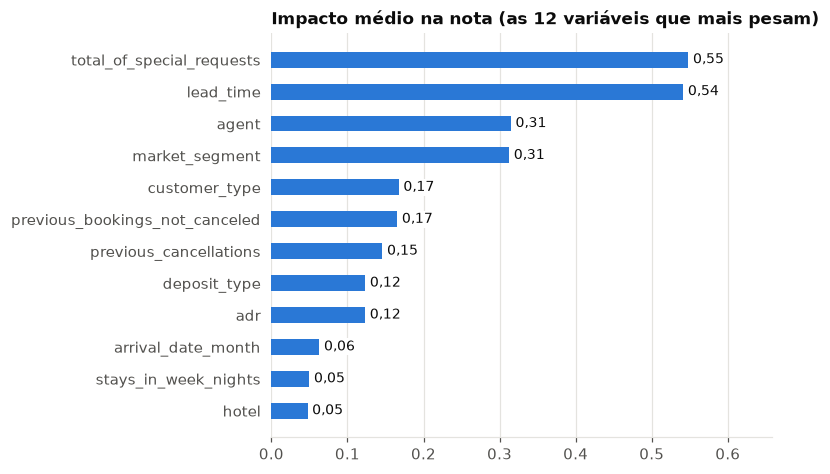

In [5]:
preparo, lgbm = modelo[0], modelo[-1]
X_validacao = validacao[modelo.feature_names_in_]

dados_preparados = preparo.transform(X_validacao)
if sparse.issparse(dados_preparados):
    dados_preparados = dados_preparados.toarray()

# a última coluna é a nota média (ponto de partida); as outras são o efeito de cada coluna do preparo
contribuicoes = lgbm.predict(dados_preparados, pred_contrib=True)[:, :-1]


def variavel_original(coluna_preparo):
    """'categoricas__market_segment_Online TA' -> 'market_segment'; 'numericas__lead_time' -> 'lead_time'."""
    bloco, resto = coluna_preparo.split("__", 1)
    if bloco == "numericas":
        return resto
    return next(c for c in modelo.feature_names_in_ if resto.startswith(c + "_"))


nomes = [variavel_original(c) for c in preparo.get_feature_names_out()]
shap_por_variavel = pd.DataFrame(contribuicoes, columns=nomes).T.groupby(level=0).sum().T

importancia = shap_por_variavel.abs().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.2))
graficos.barras_horizontais(ax, importancia.head(12), "Impacto médio na nota (as 12 variáveis que mais pesam)",
                            formato=lambda v: f"{v:.2f}".replace(".", ","))
plt.show()

**Para que lado cada variável empurra.** Efeito médio na nota por faixa ou categoria, nas quatro variáveis mais importantes para a história (laranja aumenta o risco, azul diminui).

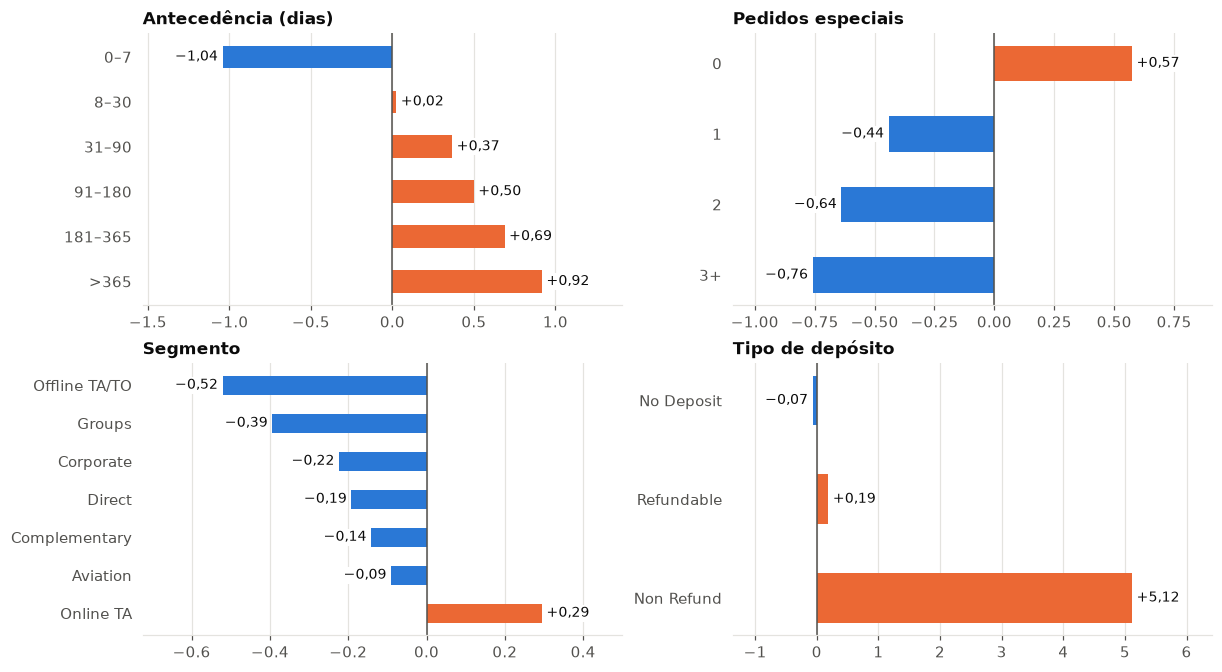

In [6]:
faixas = pd.cut(X_validacao["lead_time"], [-1, 7, 30, 90, 180, 365, np.inf],
                labels=["0–7", "8–30", "31–90", "91–180", "181–365", ">365"])
pedidos = X_validacao["total_of_special_requests"].clip(upper=3).astype(str).replace({"3": "3+"})

efeitos = {
    "Antecedência (dias)": shap_por_variavel["lead_time"].groupby(faixas, observed=True).mean(),
    "Pedidos especiais": shap_por_variavel["total_of_special_requests"].groupby(pedidos).mean(),
    "Segmento": shap_por_variavel["market_segment"].groupby(X_validacao["market_segment"]).mean().sort_values(),
    "Tipo de depósito": shap_por_variavel["deposit_type"].groupby(X_validacao["deposit_type"]).mean().sort_values(),
}

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, (titulo, valores) in zip(axes.flat, efeitos.items()):
    graficos.barras_com_sinal(ax, valores, titulo)
plt.show()

**Faz sentido de negócio?**
- **Antecedência:** quanto mais cedo a reserva, mais risco — de −1,0 na última semana a +0,9 com mais de um ano. É o mesmo padrão da EDA.
- **Pedidos especiais:** reserva sem nenhum pedido ganha +0,6; com pedidos, a nota cai. Quem pede cama de casal ou andar alto está comprometido com a viagem.
- **Segmento:** agências online aumentam o risco; operadoras, grupos e empresas diminuem.
- **Depósito:** `Non Refund` pesa muito (+5) — o modelo aprendeu o padrão dos bloqueios de grupo que vimos na auditoria. São poucas reservas (158 na validação), mas quase todas canceladas.
- Fora do gráfico: quem já cancelou antes tem efeito forte (+2,9), mas são só 136 reservas na validação.

As direções batem com o que a EDA mostrou. O ponto de atenção é a variável **mais importante**: pedidos especiais. Na auditoria ela ficou com uma ressalva — o total pode incluir pedidos feitos depois da reserva, perto da chegada, por quem de fato vai aparecer.

**Teste de robustez: e sem os pedidos especiais?** O mesmo modelo, treinado de novo com a variável zerada (uma coluna constante não carrega informação, então é o mesmo que tirá-la).

In [7]:
treino = pd.read_parquet("../data/processed/treino.parquet")
X_treino = treino[modelo.feature_names_in_]

sem_pedidos = clone(modelo).fit(X_treino.assign(total_of_special_requests=0), treino["is_canceled"])
prob_sem_pedidos = sem_pedidos.predict_proba(X_validacao.assign(total_of_special_requests=0))[:, 1]

pd.DataFrame({
    nome: {
        "ROC-AUC": roc_auc_score(y_validacao, prob),
        "PR-AUC": average_precision_score(y_validacao, prob),
        "cancelam no top 10%": y_validacao[prob >= np.quantile(prob, 0.90)].mean(),
    }
    for nome, prob in {"com pedidos especiais": prob_validacao, "sem pedidos especiais": prob_sem_pedidos}.items()
}).T.round(3)

,ROC-AUC,PR-AUC,cancelam no top 10%
com pedidos especiais,0.815,0.647,0.741
sem pedidos especiais,0.789,0.589,0.657


Sem a variável, o ROC-AUC cai de 0,815 para 0,789 e o top 10% de 74% para 66%. Ou seja, boa parte do desempenho vem dela. Se parte dos pedidos for registrada depois da reserva, o desempenho real no momento da reserva fica **entre os dois números**: 66% é o cenário conservador, 74% o otimista.